# 04 - Evaluasi Model

Notebook ini mengevaluasi model dari `03_GaussianNB` dengan metrik
multi-kelas standar, lalu secara khusus **menguji langsung** apakah
model terjebak memprediksi sumber data alih-alih tipe diabetes --
kekhawatiran yang diajukan pada `01_EDA` bagian 3.2 dan 7. Setelah itu
akurasi dipecah per sumber data, dan dampak perubahan cara imputasi
diukur terhadap cara revisi sebelumnya.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Harus sama dengan 03_GaussianNB agar split yang dibentuk ulang identik.
RANDOM_STATE = 42
TEST_SIZE = 0.2
DIAGNOSIS_LABELS = ["Normal", "Tipe 2", "Gestasional"]

model = joblib.load(MODELS_DIR / "gnb_diagnosis.joblib")
df_gabungan = pd.read_csv(PROCESSED_DIR / "merged_diagnosis.csv")
df_model = df_gabungan.drop(columns=["SumberData"])

with open(MODELS_DIR / "imputation_medians.json", encoding="utf-8") as f:
    median_latih = json.load(f)

print("Kelas yang dipelajari model:", model.classes_.tolist())
print("Median data latih untuk imputasi:", median_latih)

Kelas yang dipelajari model: ['Gestasional', 'Normal', 'Tipe 2']
Median data latih untuk imputasi: {'Age': 32.0, 'Pregnancies': 2.0, 'BMI': 28.4, 'BloodPressure': 80.0, 'Glucose': 154.0}


## Fungsi Evaluasi

Dua fungsi bantu yang dipakai berulang pada notebook ini.

In [2]:
def evaluate_predictions(y_test, y_pred, labels):
    """Confusion matrix dan metrik klasifikasi multi-kelas.

    Confusion matrix dan metrik per kelas selalu memakai daftar `labels`
    (bukan hanya kelas yang muncul di data), sehingga kelas yang tidak
    pernah muncul tetap terlihat sebagai baris/kolom kosong, bukan
    diam-diam hilang dari laporan.
    """
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    laporan = classification_report(y_test, y_pred, labels=labels, output_dict=True, zero_division=0)

    return {
        "labels": list(labels),
        "confusion_matrix": cm.tolist(),
        "akurasi": round(accuracy_score(y_test, y_pred), 4),
        "precision_macro": round(
            precision_score(y_test, y_pred, labels=labels, average="macro", zero_division=0), 4
        ),
        "recall_macro": round(
            recall_score(y_test, y_pred, labels=labels, average="macro", zero_division=0), 4
        ),
        "f1_macro": round(
            f1_score(y_test, y_pred, labels=labels, average="macro", zero_division=0), 4
        ),
        "per_kelas": {
            kelas: {
                "precision": round(laporan[kelas]["precision"], 4),
                "recall": round(laporan[kelas]["recall"], 4),
                "f1_score": round(laporan[kelas]["f1-score"], 4),
                "support": int(laporan[kelas]["support"]),
            }
            for kelas in labels
        },
    }


def evaluate_by_group(y_test, y_pred, groups):
    """Akurasi per kelompok data uji (misalnya per SumberData), dibanding
    baseline 'selalu menebak kelas terbanyak pada kelompok itu'.

    Jika akurasi suatu kelompok tidak melebihi baseline-nya, model tidak
    menambah informasi apa pun untuk kelompok tersebut.
    """
    df = pd.DataFrame(
        {
            "aktual": np.asarray(y_test),
            "prediksi": np.asarray(y_pred),
            "kelompok": np.asarray(groups),
        }
    )

    hasil = {}
    for kelompok, bagian in df.groupby("kelompok"):
        proporsi = bagian["aktual"].value_counts(normalize=True)
        hasil[str(kelompok)] = {
            "jumlah_data_uji": int(len(bagian)),
            "akurasi": round(float((bagian["aktual"] == bagian["prediksi"]).mean()), 4),
            "kelas_terbanyak": str(proporsi.index[0]),
            "baseline_kelas_terbanyak": round(float(proporsi.iloc[0]), 4),
        }
    return hasil

## Membentuk Ulang Data Uji

Split dibentuk ulang dengan `random_state` yang sama, lalu nilai hilang
diisi dengan median data latih yang disimpan `03_GaussianNB`
(`models/imputation_medians.json`) -- persis perlakuan saat pelatihan.
Sebagai pengaman, sel ini memeriksa bahwa data latih yang dibentuk
ulang benar-benar sama dengan yang dipakai melatih model.

In [3]:
X = df_model.drop(columns=["DiagnosisType"])
y = df_model["DiagnosisType"]
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df_model.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
terimputasi_uji = X_test.isna().any(axis=1)
X_train = X_train.fillna(value=median_latih)
X_test = X_test.fillna(value=median_latih)

# Jika split di sini berbeda dari 03_GaussianNB, mean per kelas data
# latih tidak akan cocok dengan yang tersimpan di dalam model.
assert np.allclose(GaussianNB().fit(X_train, y_train).theta_, model.theta_), (
    "Data latih tidak sama dengan saat pelatihan -- jalankan ulang 03_GaussianNB."
)

y_pred = model.predict(X_test)

print(f"Data uji: {len(y_test)} sampel, {int(terimputasi_uji.sum())} di antaranya memuat nilai hasil imputasi")
print(y_test.value_counts().reindex(DIAGNOSIS_LABELS))

Data uji: 859 sampel, 233 di antaranya memuat nilai hasil imputasi
DiagnosisType
Normal         531
Tipe 2          54
Gestasional    274
Name: count, dtype: int64


## Metrik Klasifikasi


In [4]:
metrik = evaluate_predictions(y_test, y_pred, labels=DIAGNOSIS_LABELS)
print("Akurasi      :", metrik["akurasi"])
print("Precision makro:", metrik["precision_macro"])
print("Recall makro   :", metrik["recall_macro"])
print("F1 makro       :", metrik["f1_macro"])
print()
pd.DataFrame(metrik["per_kelas"]).T


Akurasi      : 0.851
Precision makro: 0.7732
Recall makro   : 0.7804
F1 makro       : 0.7707



,precision,recall,f1_score,support
Normal,0.8576,0.9190,0.8873,531.0
Tipe 2,0.5294,0.6667,0.5902,54.0
Gestasional,0.9324,0.7555,0.8347,274.0


`Normal` dan `Gestasional` (kelas besar, didukung ribuan sampel)
berperforma kuat. `Tipe 2` jauh lebih lemah (precision & recall lebih
rendah) -- wajar, hanya didukung puluhan sampel uji akibat
ketidakseimbangan prior yang sudah dibahas pada `03_GaussianNB`.


## Confusion Matrix (3x3)


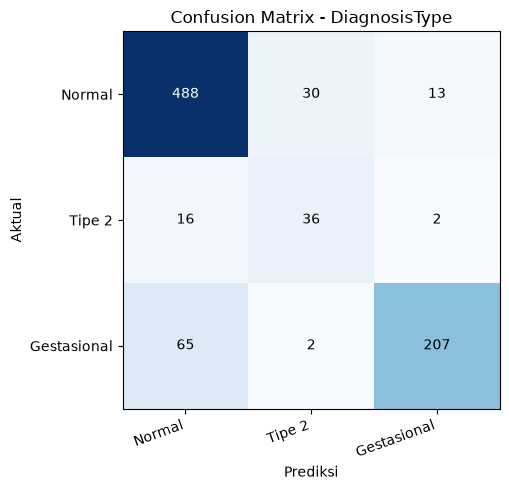

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5))
cm = metrik["confusion_matrix"]
n = len(DIAGNOSIS_LABELS)
ax.imshow(cm, cmap="Blues")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(DIAGNOSIS_LABELS, rotation=20, ha="right")
ax.set_yticklabels(DIAGNOSIS_LABELS)
nilai_maks = max(max(row) for row in cm) or 1
for i in range(n):
    for j in range(n):
        warna = "white" if cm[i][j] > nilai_maks / 2 else "black"
        ax.text(j, i, cm[i][j], ha="center", va="center", color=warna)
ax.set_title("Confusion Matrix - DiagnosisType")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()


## Pengujian Langsung: Apakah Model Menebak Sumber Data?

`01_EDA` menduga model berisiko mempelajari perbedaan sumber data
(Pima vs GDM), bukan murni tipe diabetes, karena `BMI` berbeda
sistematis antar sumber bahkan pada kelas `Normal` yang sama. Bagian
ini mengujinya langsung: latih classifier terpisah yang hanya
memprediksi `SumberData` (bukan `DiagnosisType`) dari kelima fitur
yang sama, dan lihat seberapa mudah itu dilakukan.


In [6]:
sumber_test = df_gabungan.loc[idx_test, "SumberData"]
sumber_train = df_gabungan.loc[idx_train, "SumberData"]

model_sumber = GaussianNB()
model_sumber.fit(X_train, sumber_train)
akurasi_sumber = model_sumber.score(X_test, sumber_test)

print(f"Akurasi menebak SUMBER DATA (Pima vs GDM) dari kelima fitur yang sama: {akurasi_sumber:.4f}")
print(f"Akurasi menebak DIAGNOSISTYPE (tugas sebenarnya)                    : {metrik['akurasi']:.4f}")

Akurasi menebak SUMBER DATA (Pima vs GDM) dari kelima fitur yang sama: 0.9360
Akurasi menebak DIAGNOSISTYPE (tugas sebenarnya)                    : 0.8510


**Ini bukti konkret keterbatasan model.** Jika akurasi menebak sumber
data mendekati atau melebihi akurasi menebak `DiagnosisType`, berarti
kelima fitur ini lebih "mudah" dipakai untuk mengenali studi asal
pasien daripada benar-benar mengenali tipe diabetesnya -- dan sebagian
performa model pada tugas utama kemungkinan ikut mengandalkan sinyal
ini, bukan murni pola fisiologis tipe diabetes.


## Akurasi per Sumber Data

Akurasi keseluruhan bisa menutupi kelompok pasien yang sebenarnya
tidak terbantu model. Bagian ini memecah akurasi data uji per sumber
data, lalu membandingkannya dengan baseline paling sederhana: selalu
menebak kelas terbanyak pada sumber itu (`Normal` untuk keduanya).

In [7]:
evaluasi_per_sumber = evaluate_by_group(y_test, y_pred, sumber_test)
pd.DataFrame(evaluasi_per_sumber).T

,jumlah_data_uji,akurasi,kelas_terbanyak,baseline_kelas_terbanyak
GDM,702,0.8875,Normal,0.6097
Pima,157,0.6879,Normal,0.6561


In [8]:
pd.crosstab([sumber_test.rename("SumberData"), y_test.rename("Aktual")], pd.Series(y_pred, index=y_test.index, name="Prediksi"))

Prediksi                Gestasional  Normal  Tipe 2
SumberData Aktual                                  
GDM        Gestasional          207      65       2
           Normal                11     416       1
Pima       Normal                 2      72      29
           Tipe 2                 2      16      36

**Performa model hampir seluruhnya berasal dari pasien GDM.** Untuk
pasien asal GDM model jauh di atas baseline (0,8875 vs 0,6097). Untuk
pasien asal Pima selisihnya hanya sekitar 3 poin (0,6879 vs 0,6561,
setara 5 dari 157 pasien uji) -- terlalu kecil untuk disebut lebih baik
dari sekadar selalu menebak `Normal`.

Penyebabnya sama dengan temuan perancu di atas: kelas `Normal`
didominasi pasien GDM (BMI rata-rata 23,7), sehingga pasien `Normal`
asal Pima (BMI rata-rata 30,9) tampak mirip profil `Tipe 2` di mata
model -- 29 dari 103 pasien `Normal` asal Pima pada data uji ditebak
`Tipe 2`. Akurasi keseluruhan karena itu **tidak boleh** dibaca sebagai
kemampuan model membedakan `Normal` dari `Tipe 2`.

## Dampak Perubahan Cara Imputasi

Revisi sebelumnya mengisi nilai hilang dengan median **per kelas
diagnosis, sebelum split**. Sel berikut mengulang cara lama itu pada
split yang sama, hanya sebagai pembanding terhadap cara sekarang
(median data latih, tanpa label).

In [9]:
df_lama = df_gabungan.copy()
for kolom in X.columns:
    median_per_kelas = df_lama.groupby(["SumberData", "DiagnosisType"])[kolom].transform("median")
    df_lama[kolom] = df_lama[kolom].fillna(median_per_kelas)

model_lama = GaussianNB().fit(df_lama.loc[idx_train, X.columns], y_train)
pred_lama = model_lama.predict(df_lama.loc[idx_test, X.columns])
metrik_lama = evaluate_predictions(y_test, pred_lama, labels=DIAGNOSIS_LABELS)


def ringkas(metrik_, prediksi):
    benar = np.asarray(prediksi) == y_test.values
    return {
        "akurasi": metrik_["akurasi"],
        "f1_makro": metrik_["f1_macro"],
        "recall_Gestasional": metrik_["per_kelas"]["Gestasional"]["recall"],
        "akurasi_baris_lengkap": round(float(benar[~terimputasi_uji.values].mean()), 4),
        "akurasi_baris_terimputasi": round(float(benar[terimputasi_uji.values].mean()), 4),
    }


pd.DataFrame({
    "median per kelas, sebelum split (lama)": ringkas(metrik_lama, pred_lama),
    "median data latih, tanpa label (sekarang)": ringkas(metrik, y_pred),
}).T

,akurasi,f1_makro,recall_Gestasional,akurasi_baris_lengkap,akurasi_baris_terimputasi
"median per kelas, sebelum split (lama)",0.8591,0.7708,0.8102,0.8083,0.9957
"median data latih, tanpa label (sekarang)",0.8510,0.7707,0.7555,0.7971,0.9957


Dengan cara lama akurasi 0,8591 dan recall `Gestasional` 0,8102;
dengan cara sekarang 0,8510 dan 0,7555 (turun 0,8 dan 5,5 poin). Nilai
pengisi per kelas ternyata ikut membantu model memisahkan kelas,
sehingga angka cara lama terlalu optimistis dan tidak dipakai lagi.

Satu hal **tidak** hilang dengan perbaikan ini. Karena seluruh nilai
hilang GDM ada pada kelas Non-GDM, baris hasil imputasi hampir semuanya
`Normal` (228 dari 233 baris uji) dan tetap ditebak benar 99,6% -- jauh
di atas baris yang datanya lengkap (0,7971). Akurasi keseluruhan masih
terangkat oleh baris-baris "mudah" ini; akurasi pada baris lengkap
adalah gambaran yang lebih konservatif.

## Kembali ke Analisis Permasalahan

### A. Label Diagnosis Asli, Perancu Sumber Data Tetap Ada

Dibanding dua revisi sebelumnya (`GlucoseRisk`, `InsulinResistance`,
keduanya ambang batas buatan sendiri), `DiagnosisType` memakai
diagnosis klinis asli dari dua studi nyata -- lebih valid secara
definisi label. Namun pengujian di atas membuktikan trade-off barunya:
sirkularitas berbasis atribut (seperti pada `GlucoseRisk`) digantikan
sirkularitas berbasis **sumber data**, karena kedua dataset berasal
dari populasi dan konteks klinis yang berbeda (hamil vs tidak selalu
hamil).

### B. Ketidakseimbangan Kelas

`Tipe 2` (6,2% data) jauh lebih sedikit daripada `Normal` (61,8%) dan
`Gestasional` (32%) -- konsekuensi langsung ukuran kedua studi sumber
yang timpang (768 vs 3.525 pasien).

### C. Asumsi Independensi Antar Atribut

`Age` dan `Pregnancies` tetap berkorelasi 0,54 pada Pima (`01_EDA`),
pelanggaran asumsi Naive Bayes yang tetap relevan di sini.


## Menyimpan Ringkasan Akhir


In [10]:
ringkasan = {
    "bentuk_gabungan": list(df_gabungan.shape),
    "distribusi_diagnosistype": df_gabungan["DiagnosisType"].value_counts().reindex(DIAGNOSIS_LABELS).to_dict(),
    "kelas_dipelajari_model": model.classes_.tolist(),
    "median_imputasi_data_latih": median_latih,
    "metrik": metrik,
    "akurasi_tebak_sumber_data": round(float(akurasi_sumber), 4),
    "evaluasi_per_sumber": evaluasi_per_sumber,
}

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(ringkasan, f, indent=2, ensure_ascii=False)

print(f"Tersimpan: {OUTPUT_DIR / 'metrics.json'}")

Tersimpan: D:\diabetes-risk-gnb\outputs\metrics.json


## Keterbatasan Proyek (Lengkap)

- **Perancu sumber data / status kehamilan.** Dibuktikan secara
  kuantitatif di atas -- keterbatasan paling signifikan pada revisi
  ini.
- **Union kolom dibatasi lima fitur** (`Age`, `Pregnancies`, `BMI`,
  `BloodPressure`, `Glucose`); atribut unik tiap dataset
  (`SkinThickness`, `Insulin`, `DiabetesPedigreeFunction` di Pima;
  `HDL`, `Hemoglobin`, `Family History`, dll. di GDM) tidak dipakai.
- **Ketidakseimbangan kelas berat** -- `Tipe 2` hanya 6,2% data.
- **Model nyaris tidak membantu pasien asal Pima** -- akurasi 0,6879
  vs baseline 0,6561; performa keseluruhan ditopang pasien GDM (lihat
  *Akurasi per Sumber Data*).
- **Ada-tidaknya nilai hilang berkaitan dengan label.** Seluruh nilai
  hilang GDM (1.081 `BMI`, 513 `OGTT`) ada pada kelas Non-GDM. Imputasi
  kini memakai median data latih tanpa label, sehingga nilai pengisi
  tidak lagi membocorkan label -- tetapi baris hasil imputasi tetap
  jauh lebih mudah ditebak daripada baris lengkap (lihat *Dampak
  Perubahan Cara Imputasi*).
- **Asumsi independensi antar atribut tidak sepenuhnya realistis**
  (`Age`-`Pregnancies` 0,54 pada Pima).
- **Belum ada validasi silang** -- hasil dari satu kali split dengan
  `random_state=42`.

## Aplikasi Deteksi Langsung

Model `models/gnb_diagnosis.joblib` juga dipakai `app_streamlit.py` di
akar proyek. Jalankan dengan:

```
streamlit run app_streamlit.py
```
